# LoomIQ 01 · Data Understanding and Cleaning

Get to know the UCI garment productivity dataset, find its data quality problems, and decide how to fix each one.

The final, reusable cleaning code lives in `src/loomiq/data/clean.py`. This notebook explores the data and **explains the choices**; at the end it runs that module and saves `data/interim/garments_clean.csv`.

> Feature engineering (e.g. the `met_target` column) is **not** done here. That is the job of notebook 03.

## Goals

1. Load `data/raw/garments_worker_productivity.csv` and check shape, columns and dtypes
2. Fix the `department` typo (`"sweing"`) and stray spaces (`"finishing "`)
3. Handle the missing `wip` values
4. Fix data types (`date`, and categories for `department`, `day`, `quarter`)
5. Check odd values: `actual_productivity` > 1, `Quarter5`, extreme `incentive` and `over_time`
6. Remove duplicates
7. Save the clean data to `data/interim/garments_clean.csv`

In [1]:
# Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from loomiq.config import get_path, load_config
from loomiq.data import clean
from loomiq.data.load import load_raw_productivity

config = load_config()
SEED = config["project"]["random_seed"]
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## 1. Load the raw data

Each row is **one team in one department on one day**. Key columns in factory terms:

| Column | Meaning |
|---|---|
| `team` | Team (line) number, 1 to 12 |
| `targeted_productivity` | Productivity target set for the team that day (0 to 1) |
| `actual_productivity` | Productivity actually achieved (0 to 1, can go slightly above) |
| `smv` | Standard Minute Value: standard time to make one garment |
| `wip` | Work in progress: unfinished items waiting at the line |
| `over_time` | Overtime minutes for the whole team |
| `incentive` | Bonus paid (BDT) to motivate the team |
| `idle_time`, `idle_men` | Minutes lost to stoppages, and how many workers were idle |
| `no_of_style_change` | Number of product style changes that day |
| `no_of_workers` | Team size |

In [2]:
raw = load_raw_productivity()
print(raw.shape)
raw.head()

2026-10-30 18:49:38 | INFO     | loomiq.data.load | Loaded raw productivity data: 1197 rows, 15 columns


2026-10-30 18:49:38 | INFO     | loomiq.data.load | Missing values: {'wip': 506}


(1197, 15)


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,1/1/2015,Quarter1,sweing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,1/1/2015,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,1/1/2015,Quarter1,sweing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,1/1/2015,Quarter1,sweing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,1/1/2015,Quarter1,sweing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [3]:
raw.dtypes

date                         str
quarter                      str
department                   str
day                          str
team                       int64
targeted_productivity    float64
smv                      float64
wip                      float64
over_time                  int64
incentive                  int64
idle_time                float64
idle_men                   int64
no_of_style_change         int64
no_of_workers            float64
actual_productivity      float64
dtype: object

**First observations**
- 1,197 rows and 15 columns.
- `date`, `quarter`, `department` and `day` are plain text; `date` needs converting.
- `no_of_workers` is a float, not an integer. We look at why below.

## 2. Department typo and stray spaces

In [4]:
# repr() shows hidden spaces
raw["department"].map(repr).value_counts()

department
'sweing'        691
'finishing '    257
'finishing'     249
Name: count, dtype: int64

There are **three** spellings for **two** departments: `'sweing'` (typo for *sewing*), and `'finishing'` with and without a trailing space.

**Choice:** strip whitespace, then map `sweing` → `sewing`.

In [5]:
clean.fix_department_names(raw)["department"].value_counts()

department
sewing       691
finishing    506
Name: count, dtype: int64

## 3. Missing `wip`

In [6]:
# Cleaned department names, used in the rest of the notebook
dept = clean.fix_department_names(raw)["department"]
pd.crosstab(dept, raw["wip"].isna(), margins=True).rename(columns={False: "has wip", True: "wip missing"})

wip,has wip,wip missing,All
department,,,
finishing,0,506,506
sewing,691,0,691
All,691,506,1197


All **506** missing `wip` values are in **finishing**, and *every* finishing row is missing it. Finishing (ironing, checking, packing) does not track work in progress the way sewing lines do, so the value is *not recorded* rather than *unknown*.

**Choice:** fill with **0** and add a `wip_missing` flag.
- Filling with the sewing average (~1,190) would invent backlog that never existed at finishing.
- Note that `wip_missing` is identical to `department == "finishing"` in this dataset. It is still useful as an explicit record of what was filled, and it stays correct if new data mixes the two.

## 4. Data types

### `date`
Stored as text in `M/D/YYYY` format. Convert to a real date and check that the `day` column agrees with it.

In [7]:
dates = pd.to_datetime(raw["date"], format=clean.DATE_FORMAT)
print("Range:", dates.min().date(), "to", dates.max().date(), "|", dates.nunique(), "working days")
print("day column matches date:", (dates.dt.day_name() == raw["day"]).all())
raw["day"].value_counts()

Range: 2015-01-01 to 2015-03-11 | 59 working days
day column matches date: True


day
Wednesday    208
Sunday       203
Tuesday      201
Thursday     199
Monday       199
Saturday     187
Name: count, dtype: int64

The data covers **1 Jan to 11 Mar 2015**. There are no Fridays, which is the weekly day off in Bangladesh, so the working week runs **Saturday to Thursday**. That is the order used for the `day` category.

**Choice:** `department`, `day` and `quarter` become categories (`day` and `quarter` ordered). `team` stays an integer ID.

### `no_of_workers` is a float

In [8]:
fractional = raw[raw["no_of_workers"] % 1 != 0]
print(len(fractional), "rows with fractional workers, departments:", dept[fractional.index].unique().tolist())
fractional["no_of_workers"].value_counts().head()

140 rows with fractional workers, departments: ['sewing']


no_of_workers
56.5    54
57.5    25
58.5    21
31.5    17
30.5     9
Name: count, dtype: int64

140 sewing rows have half workers (e.g. 56.5). This most likely means someone worked half a shift.

**Choice:** keep `no_of_workers` as a **float**. Converting to int would silently round away real information.

## 5. Odd values

### 5a. `actual_productivity` above 1.0

37 rows above 1.0, max = 1.12


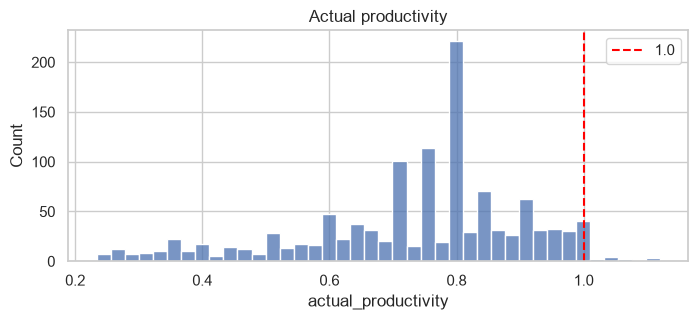

In [9]:
over_1 = raw[raw["actual_productivity"] > 1]
print(len(over_1), "rows above 1.0, max =", round(raw["actual_productivity"].max(), 3))

fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(raw["actual_productivity"], bins=40, ax=ax)
ax.axvline(1.0, color="red", linestyle="--", label="1.0")
ax.set_title("Actual productivity")
ax.legend()
plt.show()

37 rows are slightly above 1.0 (max 1.12). A team **can** beat its standard, so these are plausible, not errors.

**Choice:** keep them uncapped. Capping at 1.0 would hide the best-performing days, and the later `met_target` label is unaffected either way.

### 5b. `targeted_productivity` outlier

In [10]:
raw["targeted_productivity"].value_counts().sort_index()

targeted_productivity
0.07      1
0.35     27
0.40      2
0.50     49
0.60     57
0.65     63
0.70    242
0.75    216
0.80    540
Name: count, dtype: int64

In [11]:
cols = ["date", "department", "team", "targeted_productivity", "smv", "no_of_workers", "actual_productivity"]
team7 = raw[(raw["team"] == 7) & (dept == "sewing")][cols]
team7.loc[577:689]

,date,department,team,targeted_productivity,smv,no_of_workers,actual_productivity
577,2/2/2015,sweing,7,0.70,24.26,56.0,0.295308
595,2/3/2015,sweing,7,0.70,24.26,56.0,0.541518
611,2/4/2015,sweing,7,0.70,24.26,58.0,0.700612
633,2/5/2015,sweing,7,0.07,24.26,58.0,0.522845
650,2/7/2015,sweing,7,0.70,24.26,58.0,0.662270
672,2/8/2015,sweing,7,0.70,24.26,58.0,0.355534
689,2/9/2015,sweing,7,0.35,30.10,58.0,0.350302


One row has a target of **0.07**. The same team, with the same SMV and team size, has a target of **0.70** on the days before and after. Targets of 0.07 do not exist anywhere else, so this is a missing zero.

**Choice:** correct it to **0.70**. Left alone it would make that row look like an easy win.

### 5c. `Quarter5`

In [12]:
print(raw["quarter"].value_counts().sort_index())
print("Quarter5 dates:", sorted(raw.loc[raw["quarter"] == "Quarter5", "date"].unique()))

quarter
Quarter1    360
Quarter2    335
Quarter3    210
Quarter4    248
Quarter5     44
Name: count, dtype: int64
Quarter5 dates: ['1/29/2015', '1/31/2015']


`quarter` is the **week of the month** (Quarter1 is days 1 to 7, and so on). `Quarter5` covers days 29 to 31, but appears only on **29 and 31 January** (44 rows). It is a two-day stub of the last week, too small for a model to learn anything reliable from.

**Choice:** merge `Quarter5` into `Quarter4`.

### 5d. Extreme `incentive` and `over_time`

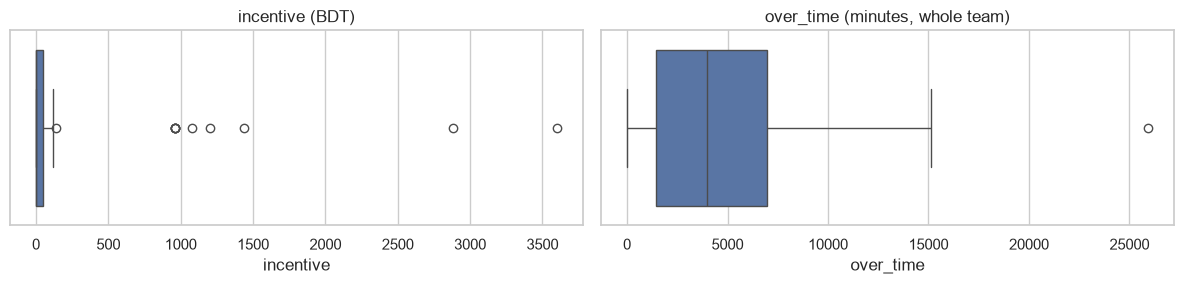

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
sns.boxplot(x=raw["incentive"], ax=axes[0]).set_title("incentive (BDT)")
sns.boxplot(x=raw["over_time"], ax=axes[1]).set_title("over_time (minutes, whole team)")
plt.tight_layout()
plt.show()

In [14]:
big_incentive = raw[raw["incentive"] > 200]
print("Dates:", big_incentive["date"].unique().tolist(), "| departments:", dept[big_incentive.index].unique().tolist())
big_incentive[cols + ["incentive"]]

Dates: ['3/9/2015'] | departments: ['finishing']


,date,department,team,targeted_productivity,smv,no_of_workers,actual_productivity,incentive
1128,3/9/2015,finishing,11,0.80,2.90,8.0,0.960625,960
1129,3/9/2015,finishing,12,0.80,4.60,9.0,0.902963,1080
1130,3/9/2015,finishing,5,0.60,3.94,12.0,0.864343,2880
1133,3/9/2015,finishing,9,0.75,2.90,15.0,0.841000,3600
1137,3/9/2015,finishing,3,0.80,4.60,12.0,0.795417,1440
1138,3/9/2015,finishing,4,0.75,3.94,8.0,0.795388,960
1139,3/9/2015,finishing,1,0.75,3.94,8.0,0.794567,960
1143,3/9/2015,finishing,2,0.70,3.90,10.0,0.682500,1200
1148,3/9/2015,finishing,10,0.70,2.90,8.0,0.477292,960
1149,3/9/2015,finishing,8,0.65,3.90,8.0,0.264062,960


Every incentive above 200 is in **finishing on a single day (9 March 2015)**, ranging from 960 to 3,600. Most days, incentive is 0 (the median). This looks like a real one-off bonus event, not a typing error.

**Choice:** keep the values. Tree models (RandomForest, XGBoost) split on thresholds, so large values do not distort them the way they would a linear model.

In [15]:
ot_per_worker = raw["over_time"] / raw["no_of_workers"]
print(ot_per_worker.describe().round(1))
raw.loc[raw["over_time"].nlargest(3).index, cols + ["over_time"]]

count    1197.0
mean      148.3
std        86.0
min         0.0
25%       120.0
50%       120.0
75%       180.0
max       720.0
dtype: float64


,date,department,team,targeted_productivity,smv,no_of_workers,actual_productivity,over_time
146,1/8/2015,sweing,11,0.35,12.52,54.0,0.349951,25920
138,1/8/2015,sweing,12,0.80,11.61,31.5,0.800107,15120
383,1/22/2015,finishing,1,0.70,3.94,25.0,0.649662,15000


The largest `over_time` (25,920 min) belongs to a 54-person team, so it is 480 min (8 h) per worker. That is high, but the per-worker view puts it in a believable range.

**Choice:** keep it. Notebook 03 will add `overtime_per_worker` so the model sees the fairer per-person number.

### 5e. `idle_time` and `idle_men`

In [16]:
raw.loc[raw["idle_time"] > 0, ["date", "team", "idle_time", "idle_men", "no_of_workers", "actual_productivity"]]

,date,team,idle_time,idle_men,no_of_workers,actual_productivity
615,2/4/2015,5,90.0,10,58.5,0.650835
617,2/4/2015,4,150.0,15,55.5,0.350706
650,2/7/2015,7,270.0,45,58.0,0.662270
654,2/7/2015,8,300.0,37,57.0,0.365319
775,2/15/2015,8,2.0,10,59.0,0.700573
798,2/16/2015,8,2.0,10,59.0,0.621972
818,2/17/2015,8,5.0,30,58.0,0.600983
822,2/17/2015,10,8.0,35,49.0,0.302117
841,2/18/2015,10,8.0,35,47.0,0.303574
843,2/18/2015,8,4.5,30,57.0,0.251399


Only 18 rows have any idle time, mostly in February. The 90 to 300 minute rows (early Feb) look like real stoppages such as machine breakdowns or power cuts, and productivity drops on those days.

**Choice:** keep them. They are rare but real events, which is exactly what we want the model to learn from.

## 6. Duplicates

In [17]:
print("Exact duplicate rows:", raw.duplicated().sum())

Exact duplicate rows: 0


No duplicates. The pipeline still runs `drop_duplicates()` so it is safe on future data.

## 7. Run the cleaning pipeline and save

`clean.clean_productivity` runs every step above in order, then `validate_clean` checks that there are no missing values, no unexpected departments, no duplicates, and that `day` matches `date`.

In [18]:
df = clean.clean_productivity(raw)
df.info()

2026-10-30 18:49:39 | INFO     | loomiq.data.clean | Removed 0 duplicate rows


2026-10-30 18:49:39 | INFO     | loomiq.data.clean | Odd values kept on purpose: {'actual_productivity_above_1': 37, 'incentive_outliers': 11, 'over_time_outliers': 1, 'rows_with_idle_time': 18, 'fractional_workers': 140}


2026-10-30 18:49:39 | INFO     | loomiq.data.clean | Cleaned data: 1197 rows, 16 columns


<class 'pandas.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   date                   1197 non-null   datetime64[us]
 1   quarter                1197 non-null   category      
 2   department             1197 non-null   category      
 3   day                    1197 non-null   category      
 4   team                   1197 non-null   int64         
 5   targeted_productivity  1197 non-null   float64       
 6   smv                    1197 non-null   float64       
 7   wip                    1197 non-null   float64       
 8   over_time              1197 non-null   int64         
 9   incentive              1197 non-null   int64         
 10  idle_time              1197 non-null   float64       
 11  idle_men               1197 non-null   int64         
 12  no_of_style_change     1197 non-null   int64         
 13  no_of_workers 

In [19]:
print("Missing values:", df.isna().sum().sum())
print("Departments:", list(df["department"].cat.categories))
print("Quarters:", list(df["quarter"].cat.categories))
print("Min target:", df["targeted_productivity"].min())
print("Odd values kept:", clean.find_odd_values(df))

Missing values: 0
Departments: ['sewing', 'finishing']
Quarters: ['Quarter1', 'Quarter2', 'Quarter3', 'Quarter4']
Min target: 0.35
Odd values kept: {'actual_productivity_above_1': 37, 'incentive_outliers': 11, 'over_time_outliers': 1, 'rows_with_idle_time': 18, 'fractional_workers': 140}


In [20]:
path = clean.save_clean(df)
print("Saved to", path.relative_to(get_path("raw_data").parents[1]))

# Reading it back restores the dtypes that CSV loses
clean.load_clean_productivity().dtypes

2026-10-30 18:49:39 | INFO     | loomiq.data.clean | Saved cleaned data to D:\Projects\LoomIQ\LoomIQ-Garment-Factory-Intelligence-Platform\data\interim\garments_clean.csv


Saved to data\interim\garments_clean.csv


date                     datetime64[us]
quarter                        category
department                     category
day                            category
team                              int64
targeted_productivity           float64
smv                             float64
wip                             float64
over_time                         int64
incentive                         int64
idle_time                       float64
idle_men                          int64
no_of_style_change                int64
no_of_workers                   float64
actual_productivity             float64
wip_missing                        bool
dtype: object

## Summary of cleaning decisions

| Issue | Rows | Decision |
|---|---|---|
| `department` typo `sweing` / trailing spaces | 691 / 257 | Strip spaces, `sweing` → `sewing` |
| Missing `wip` (all finishing) | 506 | Fill with 0, add `wip_missing` flag |
| `date` stored as text | all | Convert to datetime |
| `department`, `day`, `quarter` as text | all | Categories (`day`: Sat to Thu, `quarter`: Q1 to Q4) |
| `targeted_productivity` = 0.07 | 1 | Typo, corrected to 0.70 |
| `Quarter5` (29 and 31 Jan only) | 44 | Merged into `Quarter4` |
| Fractional `no_of_workers` | 140 | Kept as float (half-shift workers) |
| `actual_productivity` > 1.0 | 37 | Kept, plausible over-performance |
| Extreme `incentive` (one bonus day) | 10 | Kept |
| Extreme `over_time` / `idle_time` | few | Kept, real events |
| Duplicates | 0 | None found; dedupe step kept for safety |

**Output:** `data/interim/garments_clean.csv` with 1,197 rows and 16 columns.

**Next:** notebook 02 (EDA) uses `clean.load_clean_productivity()` to explore what drives teams to hit or miss their targets.